# Budget Optimization

## Load data and configure the optimization

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize

# Load the cleaned dataset prepared in Notebook 1.
DATA_PATH = "../data/mmm_eda_clean.csv"
df = pd.read_csv(DATA_PATH, parse_dates=["DATE"])
df = df.sort_values("DATE").reset_index(drop=True)

In [2]:
# The five paid media channels used in our MMM.
MEDIA_COLS = [
    "tv_S",
    "ooh_S",
    "print_S",
    "facebook_S",
    "search_S",
]

# Use the same provisional adstock and Hill saturation settings
# used in Notebook 3.
DECAY = 0.5
SLOPE = 1.0

# Half-saturation parameters from the Notebook 3 model configuration.
# Keep these consistent with the values used to fit your MMM.
HALF_SATURATION = {
    "tv_S": 19094.3911,
    "ooh_S": 71559.9820,
    "print_S": 6410.5009,
    "facebook_S": 3445.5238,
    "search_S": 8069.9394,
}

# Fitted non-negative media coefficients from Notebook 3.
# These are required to calculate modeled channel contributions.
MEDIA_COEFFICIENTS = {
    "tv_S": 704265.0978,
    "ooh_S": 56687.2489,
    "print_S": 252240.9431,
    "facebook_S": 256060.4398,
    "search_S": 102314.0391,
}

In [3]:
# Basic data checks.
assert set(MEDIA_COLS).issubset(df.columns)
assert not df[MEDIA_COLS].isna().any().any()
assert (df[MEDIA_COLS] >= 0).all().all()

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("Date range:", df["DATE"].min().date(), "to", df["DATE"].max().date())
print("Media channels:", MEDIA_COLS)

print("\nHistorical average weekly media spend:")
display(df[MEDIA_COLS].mean().rename("Average Weekly Spend").to_frame().round(2))

print("\nHistorical total average weekly budget:")
print(f"{df[MEDIA_COLS].mean().sum():,.2f}")

Dataset loaded successfully.
Dataset shape: (208, 12)
Date range: 2015-11-23 to 2019-11-11
Media channels: ['tv_S', 'ooh_S', 'print_S', 'facebook_S', 'search_S']

Historical average weekly media spend:


,Average Weekly Spend
tv_S,14843.69
ooh_S,43217.94
print_S,3728.63
facebook_S,2145.66
search_S,5915.51



Historical total average weekly budget:
69,851.44


## Define the current allocation and spending bounds

In [4]:
# Current allocation: historical average weekly spend per channel.
current_allocation = df[MEDIA_COLS].mean().to_numpy(dtype=float)

# Keep the total weekly budget fixed.
TOTAL_BUDGET = float(current_allocation.sum())

# Define plausible channel-specific bounds based on observed spending.
# Lower bound: zero is allowed because some channels have inactive weeks.
# Upper bound: the 95th percentile of historical weekly spend.
lower_bounds = np.zeros(len(MEDIA_COLS), dtype=float)

upper_bounds = np.array([
    float(df[channel].quantile(0.95))
    for channel in MEDIA_COLS
])

bounds_df = pd.DataFrame({
    "Channel": MEDIA_COLS,
    "Current_Avg_Weekly_Spend": current_allocation,
    "Minimum_Weekly_Spend": lower_bounds,
    "Maximum_Weekly_Spend": upper_bounds,
})

bounds_df["Current_Budget_Share_Pct"] = (
    bounds_df["Current_Avg_Weekly_Spend"] / TOTAL_BUDGET * 100
)

print(f"Fixed total weekly budget: {TOTAL_BUDGET:,.2f}")
print("\nCurrent allocation and optimization bounds:")
display(bounds_df.round(2))

Fixed total weekly budget: 69,851.44

Current allocation and optimization bounds:


,Channel,Current_Avg_Weekly_Spend,Minimum_Weekly_Spend,Maximum_Weekly_Spend,Current_Budget_Share_Pct
0,tv_S,14843.69,0.0,76099.83,21.25
1,ooh_S,43217.94,0.0,219293.84,61.87
2,print_S,3728.63,0.0,19052.55,5.34
3,facebook_S,2145.66,0.0,8028.00,3.07
4,search_S,5915.51,0.0,15260.67,8.47


In [5]:
# Check that the current allocation is feasible under these bounds.
assert np.isclose(current_allocation.sum(), TOTAL_BUDGET)
assert np.all(current_allocation >= lower_bounds)
assert np.all(current_allocation <= upper_bounds)

# Check that the total budget can fit within the combined channel bounds.
assert lower_bounds.sum() <= TOTAL_BUDGET <= upper_bounds.sum()

print("\nAll budget feasibility checks passed.")


All budget feasibility checks passed.


## Define the response function and optimization objective

In [6]:
def hill_saturation(x, half_saturation, slope=1.0):
    """
    Hill saturation function.
    Returns a value between 0 and 1 for non-negative inputs.
    """
    x = np.asarray(x, dtype=float)
    x = np.maximum(x, 0.0)

    numerator = x ** slope
    denominator = (half_saturation ** slope) + numerator

    return np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator, dtype=float),
        where=denominator != 0,
    )

In [7]:
def steady_state_channel_contribution(channel, weekly_spend):
    """
    Model-implied weekly contribution under constant weekly spend.

    Assumes geometric adstock has reached steady state:
        adstock = weekly_spend / (1 - decay)

    This is a scenario estimate, not a causal revenue estimate.
    """
    weekly_spend = max(float(weekly_spend), 0.0)

    adstock_value = weekly_spend / (1.0 - DECAY)

    saturated_value = hill_saturation(
        adstock_value,
        half_saturation=HALF_SATURATION[channel],
        slope=SLOPE,
    )

    return MEDIA_COEFFICIENTS[channel] * float(saturated_value)

In [8]:
def total_modeled_contribution(allocation):
    """Sum modeled steady-state contribution across all channels."""
    return sum(
        steady_state_channel_contribution(channel, spend)
        for channel, spend in zip(MEDIA_COLS, allocation)
    )

In [9]:
# Evaluate the current allocation as the benchmark.
current_contribution = total_modeled_contribution(current_allocation)

print(f"Current weekly budget: {TOTAL_BUDGET:,.2f}")
print(f"Current modeled weekly media contribution: {current_contribution:,.2f}")

Current weekly budget: 69,851.44
Current modeled weekly media contribution: 798,102.58


## Optimize the allocation

In [10]:
def objective(allocation):
    # scipy.optimize.minimize minimizes, so negate the contribution.
    return -total_modeled_contribution(allocation)

In [11]:
constraints = [
    {
        "type": "eq",
        "fun": lambda allocation: np.sum(allocation) - TOTAL_BUDGET,
    }
]

optimization_result = minimize(
    objective,
    x0=current_allocation.copy(),
    method="SLSQP",
    bounds=list(zip(lower_bounds, upper_bounds)),
    constraints=constraints,
    options={
        "maxiter": 2000,
        "ftol": 1e-9,
        "disp": False,
    },
)

In [12]:
if not optimization_result.success:
    raise RuntimeError(
        f"Optimization failed: {optimization_result.message}"
    )

optimized_allocation = optimization_result.x
optimized_contribution = total_modeled_contribution(optimized_allocation)

assert np.isclose(optimized_allocation.sum(), TOTAL_BUDGET, atol=1e-4)
assert np.all(optimized_allocation >= lower_bounds - 1e-6)
assert np.all(optimized_allocation <= upper_bounds + 1e-6)

In [13]:
print("Optimization successful.")
print("Optimizer message:", optimization_result.message)
print(f"Optimized total weekly budget: {optimized_allocation.sum():,.2f}")
print(f"Optimized modeled weekly media contribution: {optimized_contribution:,.2f}")
print(f"Current modeled weekly media contribution: {current_contribution:,.2f}")
print(
    "Modeled contribution change (%):",
    round(
        (optimized_contribution / current_contribution - 1) * 100,
        2,
    ),
)

Optimization successful.
Optimizer message: Optimization terminated successfully
Optimized total weekly budget: 69,851.44
Optimized modeled weekly media contribution: 1,052,166.09
Current modeled weekly media contribution: 798,102.58
Modeled contribution change (%): 31.83


## Compare current vs. optimized channel allocations

In [14]:
allocation_comparison = pd.DataFrame({
    "Channel": MEDIA_COLS,
    "Current_Weekly_Spend": current_allocation,
    "Optimized_Weekly_Spend": optimized_allocation,
})

# Calculate absolute and percentage changes in spending
allocation_comparison["Budget_Change"] = (
    allocation_comparison["Optimized_Weekly_Spend"]
    - allocation_comparison["Current_Weekly_Spend"]
)

allocation_comparison["Current_Budget_Share_Pct"] = (
    allocation_comparison["Current_Weekly_Spend"] / TOTAL_BUDGET * 100
)

allocation_comparison["Optimized_Budget_Share_Pct"] = (
    allocation_comparison["Optimized_Weekly_Spend"] / TOTAL_BUDGET * 100
)

In [15]:
# Calculate each channel's modeled contribution before and after optimization
allocation_comparison["Current_Modeled_Contribution"] = [
    steady_state_channel_contribution(channel, spend)
    for channel, spend in zip(MEDIA_COLS, current_allocation)
]

allocation_comparison["Optimized_Modeled_Contribution"] = [
    steady_state_channel_contribution(channel, spend)
    for channel, spend in zip(MEDIA_COLS, optimized_allocation)
]

allocation_comparison["Contribution_Change"] = (
    allocation_comparison["Optimized_Modeled_Contribution"]
    - allocation_comparison["Current_Modeled_Contribution"]
)

In [16]:
# Display a rounded comparison table
display(
    allocation_comparison
    .round(2)
    .sort_values("Budget_Change", ascending=False)
    .reset_index(drop=True)
)

# Verify the budget remains unchanged
assert np.isclose(
    allocation_comparison["Current_Weekly_Spend"].sum(),
    TOTAL_BUDGET
)
assert np.isclose(
    allocation_comparison["Optimized_Weekly_Spend"].sum(),
    TOTAL_BUDGET,
    atol=1e-4
)

print(f"\nCurrent budget total:   {allocation_comparison['Current_Weekly_Spend'].sum():,.2f}")
print(f"Optimized budget total: {allocation_comparison['Optimized_Weekly_Spend'].sum():,.2f}")

,Channel,Current_Weekly_Spend,Optimized_Weekly_Spend,Budget_Change,Current_Budget_Share_Pct,Optimized_Budget_Share_Pct,Current_Modeled_Contribution,Optimized_Modeled_Contribution,Contribution_Change
0,tv_S,14843.69,39761.76,24918.06,21.25,56.92,428598.34,567905.34,139307.00
1,print_S,3728.63,13889.93,10161.30,5.34,19.88,135640.27,204947.18,69306.91
2,facebook_S,2145.66,8028.00,5882.35,3.07,11.49,142026.49,210819.77,68793.28
3,search_S,5915.51,8171.75,2256.23,8.47,11.70,60825.19,68493.80,7668.61
4,ooh_S,43217.94,0.00,-43217.94,61.87,0.00,31012.28,0.00,-31012.28



Current budget total:   69,851.44
Optimized budget total: 69,851.44


## Visualize budget reallocation

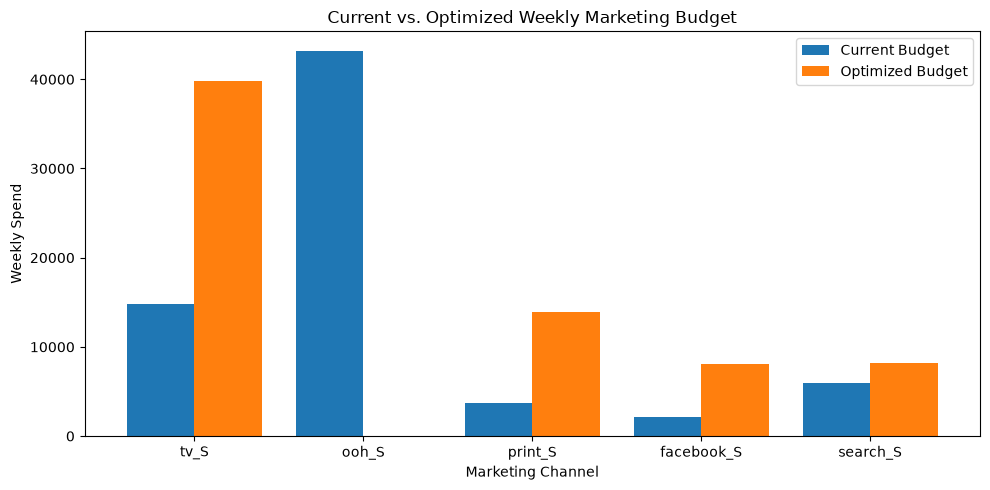

In [17]:
plot_df = allocation_comparison.set_index("Channel")

# Chart 1: Weekly budget allocation
ax = plot_df[
    ["Current_Weekly_Spend", "Optimized_Weekly_Spend"]
].plot(
    kind="bar",
    figsize=(10, 5),
    width=0.8
)

ax.set_title("Current vs. Optimized Weekly Marketing Budget")
ax.set_xlabel("Marketing Channel")
ax.set_ylabel("Weekly Spend")
ax.legend(["Current Budget", "Optimized Budget"])
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

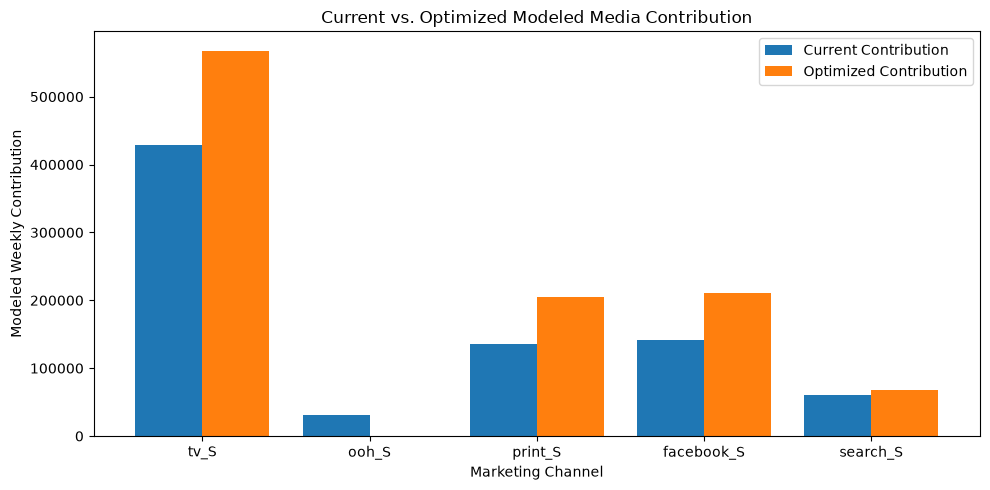

In [18]:
# Chart 2: Modeled weekly contribution
ax = plot_df[
    ["Current_Modeled_Contribution", "Optimized_Modeled_Contribution"]
].plot(
    kind="bar",
    figsize=(10, 5),
    width=0.8
)

ax.set_title("Current vs. Optimized Modeled Media Contribution")
ax.set_xlabel("Marketing Channel")
ax.set_ylabel("Modeled Weekly Contribution")
ax.legend(["Current Contribution", "Optimized Contribution"])
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

## Sensitivity analysis for the Hill slope

In [19]:
def contribution_with_slope(allocation, hill_slope):
    """Calculate total steady-state modeled contribution for a given Hill slope."""
    total = 0.0

    for channel, spend in zip(MEDIA_COLS, allocation):
        # Convert weekly spend to steady-state adstock
        adstock_value = max(float(spend), 0.0) / (1.0 - DECAY)

        # Apply Hill saturation using the selected slope
        saturated_value = hill_saturation(
            adstock_value,
            half_saturation=HALF_SATURATION[channel],
            slope=hill_slope
        )

        total += MEDIA_COEFFICIENTS[channel] * float(saturated_value)

    return total

In [20]:
# Test a lower, original, and higher Hill slope
SLOPE_SCENARIOS = [0.8, 1.0, 1.2]
sensitivity_results = []
sensitivity_allocations = []

for slope_value in SLOPE_SCENARIOS:

    # Optimize the allocation for this slope
    result = minimize(
        fun=lambda allocation: -contribution_with_slope(
            allocation, slope_value
        ),
        x0=current_allocation.copy(),
        method="SLSQP",
        bounds=list(zip(lower_bounds, upper_bounds)),
        constraints=[
            {
                "type": "eq",
                "fun": lambda allocation: np.sum(allocation) - TOTAL_BUDGET
            }
        ],
        options={"maxiter": 2000, "ftol": 1e-9, "disp": False}
    )

    if not result.success:
        raise RuntimeError(
            f"Optimization failed for Hill slope {slope_value}: "
            f"{result.message}"
        )

    scenario_allocation = result.x

    # Evaluate both current and optimized allocations under the same slope
    current_value = contribution_with_slope(
        current_allocation, slope_value
    )
    optimized_value = contribution_with_slope(
        scenario_allocation, slope_value
    )

    sensitivity_results.append({
        "Hill_Slope": slope_value,
        "Current_Contribution": current_value,
        "Optimized_Contribution": optimized_value,
        "Improvement_Pct": (
            (optimized_value - current_value) / current_value * 100
            if current_value != 0 else np.nan
        )
    })

    allocation_row = {"Hill_Slope": slope_value}
    allocation_row.update(dict(zip(MEDIA_COLS, scenario_allocation)))
    sensitivity_allocations.append(allocation_row)

In [21]:
# Display contribution improvement across scenarios
sensitivity_df = pd.DataFrame(sensitivity_results)
display(sensitivity_df.round(2))

# Display recommended channel spending for each slope
sensitivity_allocation_df = pd.DataFrame(sensitivity_allocations)
display(sensitivity_allocation_df.round(2))

# Verify that each optimized allocation respects the total budget
for row in sensitivity_allocations:
    scenario_spend = sum(row[channel] for channel in MEDIA_COLS)
    assert np.isclose(scenario_spend, TOTAL_BUDGET, atol=1e-4)

print("Sensitivity analysis completed. All optimized budgets satisfy the fixed-budget constraint.")

,Hill_Slope,Current_Contribution,Optimized_Contribution,Improvement_Pct
0,0.8,776047.92,990467.97,27.63
1,1.0,798102.58,1052166.12,31.83
2,1.2,819826.95,1104696.15,34.75


,Hill_Slope,tv_S,ooh_S,print_S,facebook_S,search_S
0,0.8,39745.93,663.02,13993.43,8028.0,7421.06
1,1.0,39751.14,0.00,13890.64,8028.0,8181.66
2,1.2,39322.59,0.00,13670.26,8028.0,8830.58


Sensitivity analysis completed. All optimized budgets satisfy the fixed-budget constraint.


## Visualize sensitivity results

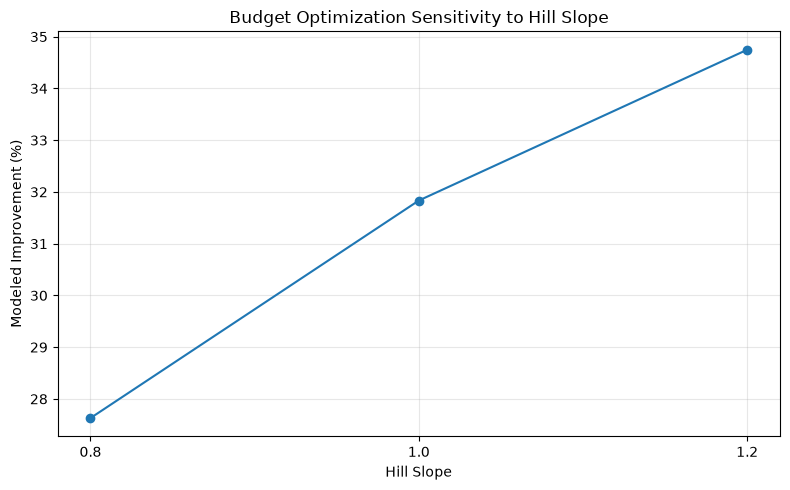

In [22]:
# Chart 1: Modeled contribution improvement by Hill slope
plt.figure(figsize=(8, 5))
plt.plot(
    sensitivity_df["Hill_Slope"],
    sensitivity_df["Improvement_Pct"],
    marker="o"
)
plt.title("Budget Optimization Sensitivity to Hill Slope")
plt.xlabel("Hill Slope")
plt.ylabel("Modeled Improvement (%)")
plt.xticks(SLOPE_SCENARIOS)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

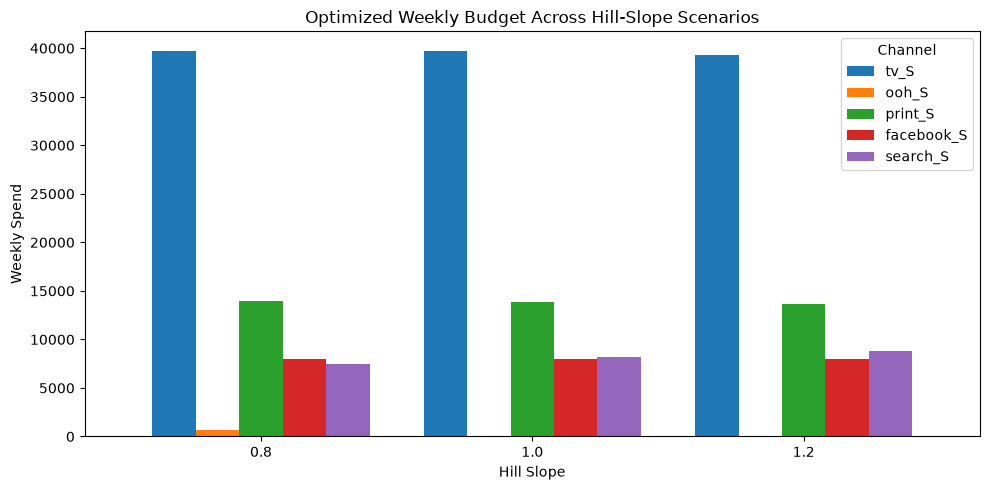

Sensitivity charts generated successfully.


In [23]:
# Chart 2: Optimized channel allocation across Hill slopes
allocation_plot_df = sensitivity_allocation_df.set_index("Hill_Slope")[
    MEDIA_COLS
]

ax = allocation_plot_df.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.8
)
ax.set_title("Optimized Weekly Budget Across Hill-Slope Scenarios")
ax.set_xlabel("Hill Slope")
ax.set_ylabel("Weekly Spend")
ax.legend(title="Channel")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print("Sensitivity charts generated successfully.")

### Stage 5: Budget Optimization

1. Budget optimization: Used constrained numerical optimization to maximize modeled steady-state media contribution while maintaining the historical average weekly budget of 69,851.44 and respecting channel-specific spending bounds.

2. Allocation findings: Under the original Hill-slope assumption, modeled weekly contribution increased from 798,102.58 to 1,052,166.12, an improvement of 31.83%. The optimizer favored TV, Print, Facebook, and Search, while assigning zero budget to OOH.

3. Sensitivity and limitations: The modeled improvement ranged from 27.63% to 34.75% across Hill slopes of 0.8–1.2. Since the dataset is simulated and the response curves rely on assumed adstock and fitted parameters, these results are exploratory recommendations rather than validated causal effects or guaranteed revenue gains.